# Шум, Gaussian/Box/Median и качество восстановления

**

**Цель:** Сравнить шумоподавление и проверить компромисс: сохранение деталей против уменьшения шума.

**Входные данные:** `images/source/camera.png`, `images/noisy/camera_gaussian_sigma22.png`, `images/noisy/camera_salt_pepper_7pct.png`

**Формула:** PSNR = 10 log₁₀(MAX²/MSE), где MAX=255 для uint8.

## Последовательность выполнения

1. Показать оригинал и два загрязнённых изображения в одинаковом масштабе. Кратко описать распределения шума.
2. Для каждого шумового входа применить Box(5×5), Gaussian(σ=0.8, 1.5, 3.0), Median(5×5).
3. Для каждого результата вычислить MSE и PSNR относительно camera.png. Вывести таблицу, отсортированную по PSNR.
4. Вырезать один и тот же участок изображения (например, [120:220,120:220]), показать на уровне пикселей и обсудить границы.
5. Построить график PSNR(σ) для GaussianBlur, σ ∈ [0.5,3] с шагом 0.5 на гауссовом шуме.
6. Объяснить, почему медиана нелинейна и почему на разных шумах может побеждать разный фильтр.

**Ожидаемая проверка:** Для корректного сравнения используйте один оригинал; PSNR → +∞ при нулевой MSE. Нельзя судить о качестве лишь по количеству размытия.

**Оценивание / 10:** Проверка шумов — 1; фильтры — 3; MSE/PSNR — 3; график и вывод — 3.

**Вопросы:**
- Почему фильтр медианы нельзя представить фиксированным свёрточным ядром?
- В чём недостаток PSNR при оценке качества изображения?

Шум             | Фильтр               | MSE        | PSNR (dB) 
--------------------------------------------------------------
Гауссов         | Box 5x5              | 160.68     | 26.07     
Гауссов         | Gaussian sigma=0.8   | 109.50     | 27.74     
Гауссов         | Gaussian sigma=1.5   | 129.14     | 27.02     
Гауссов         | Gaussian sigma=3.0   | 189.31     | 25.36     
Гауссов         | Median 5x5           | 141.06     | 26.64     
Импульсный      | Box 5x5              | 233.06     | 24.46     
Импульсный      | Gaussian sigma=0.8   | 271.29     | 23.80     
Импульсный      | Gaussian sigma=1.5   | 211.66     | 24.87     
Импульсный      | Gaussian sigma=3.0   | 243.30     | 24.27     
Импульсный      | Median 5x5           | 108.18     | 27.79     

[Контрольные вопросы]:
1) Медианный фильтр является нелинейным ранговым фильтром, поэтому он эффективно удаляет выбросы (битые пиксели), заменяя их медианой окрестности без размытия резких перепадов.
2) Гауссов фильтр опт

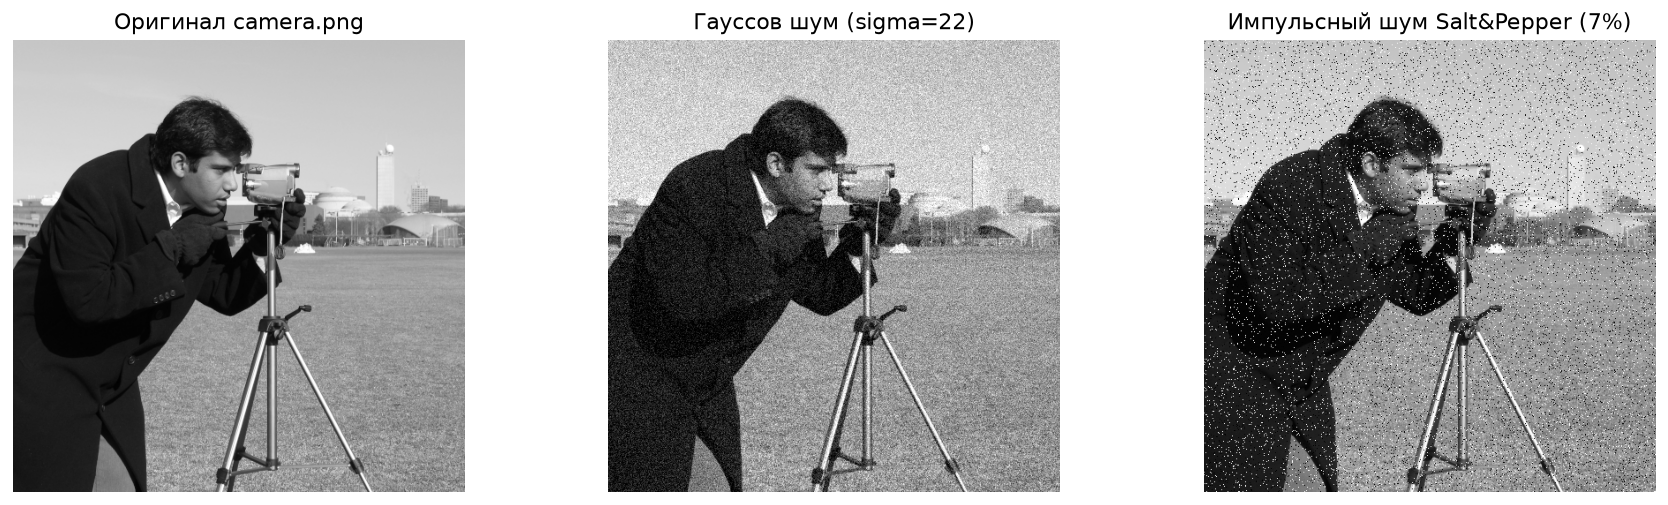

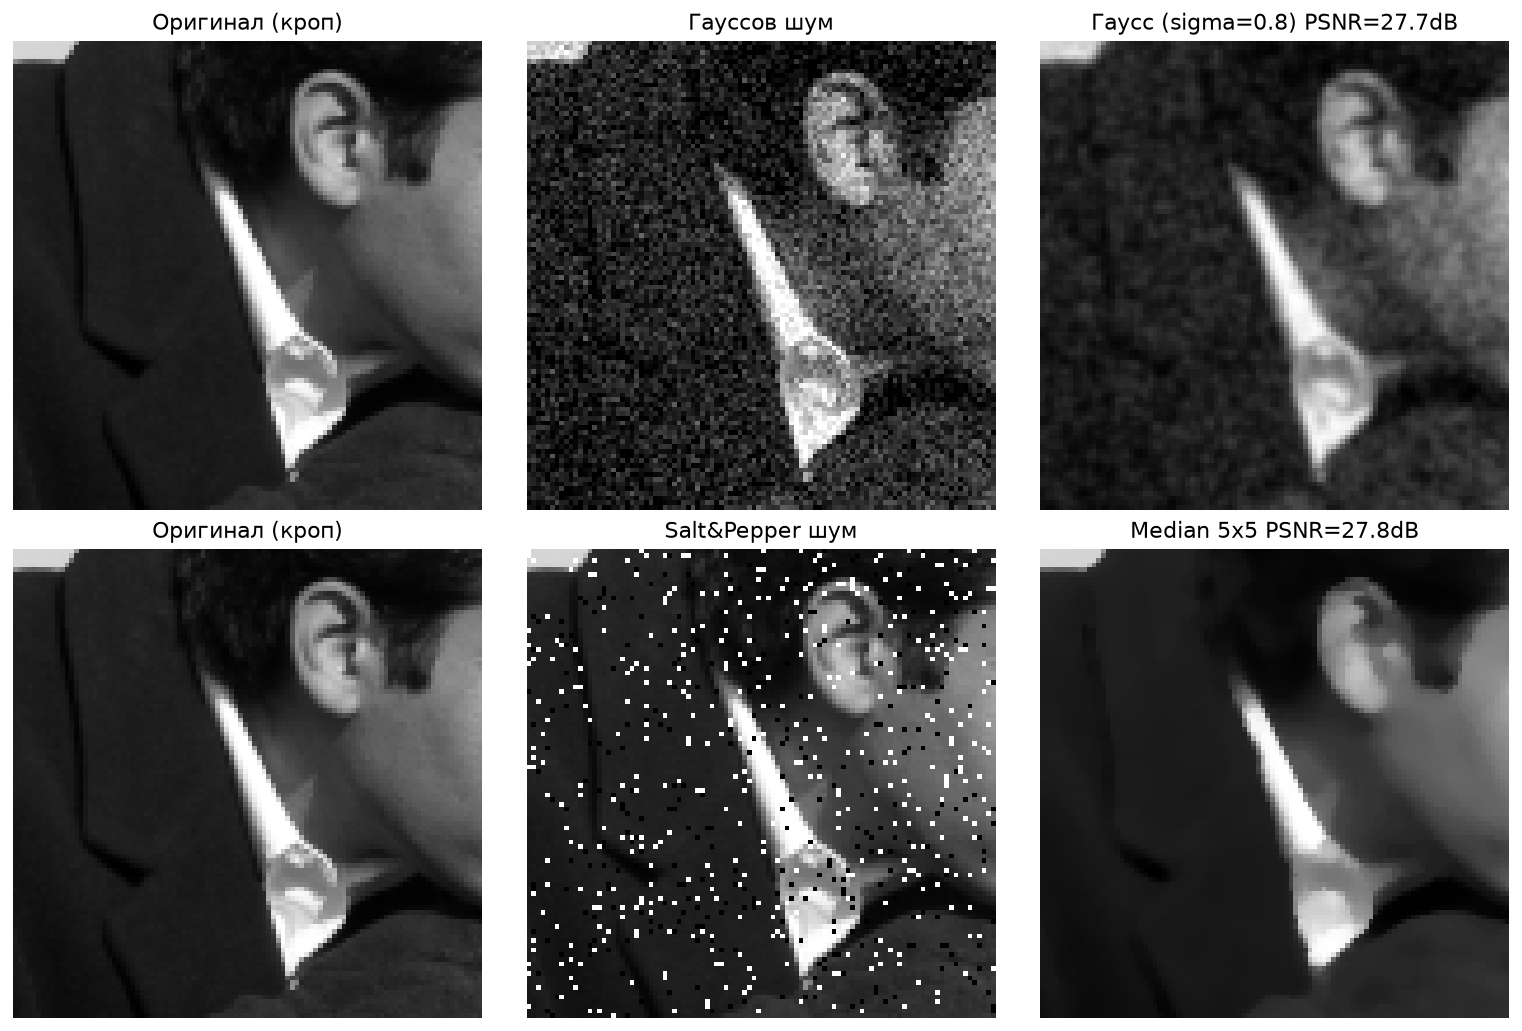

In [1]:
# Полное выполнение заданий Лабораторной работы №3
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
clean = cv2.imread(str(R/'images/source/camera.png'), cv2.IMREAD_GRAYSCALE)
g_noisy = cv2.imread(str(R/'images/noisy/camera_gaussian_sigma22.png'), cv2.IMREAD_GRAYSCALE)
sp_noisy = cv2.imread(str(R/'images/noisy/camera_salt_pepper_7pct.png'), cv2.IMREAD_GRAYSCALE)
assert clean is not None and g_noisy is not None and sp_noisy is not None

# 1. Визуализация оригинала и загрязненных изображений
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(clean, cmap='gray'); axes[0].set_title("Оригинал camera.png"); axes[0].axis('off')
axes[1].imshow(g_noisy, cmap='gray'); axes[1].set_title("Гауссов шум (sigma=22)"); axes[1].axis('off')
axes[2].imshow(sp_noisy, cmap='gray'); axes[2].set_title("Импульсный шум Salt&Pepper (7%)"); axes[2].axis('off')
plt.tight_layout()
plt.show()

# 2-3. Фильтрация и вычисление MSE и PSNR
def calc_metrics(orig, test):
    mse = np.mean((orig.astype(float) - test.astype(float)) ** 2)
    if mse < 1e-12:
        return 0.0, float('inf')
    psnr = 10.0 * np.log10((255.0 ** 2) / mse)
    return mse, psnr

filters = {
    'Box 5x5': lambda img: cv2.blur(img, (5, 5)),
    'Gaussian sigma=0.8': lambda img: cv2.GaussianBlur(img, (5, 5), 0.8),
    'Gaussian sigma=1.5': lambda img: cv2.GaussianBlur(img, (5, 5), 1.5),
    'Gaussian sigma=3.0': lambda img: cv2.GaussianBlur(img, (7, 7), 3.0),
    'Median 5x5': lambda img: cv2.medianBlur(img, 5)
}

print(f"{'Шум':<15} | {'Фильтр':<20} | {'MSE':<10} | {'PSNR (dB)':<10}")
print("-" * 62)

best_g = {}
best_sp = {}
for name, fn in filters.items():
    den_g = fn(g_noisy)
    mse_g, psnr_g = calc_metrics(clean, den_g)
    best_g[name] = (mse_g, psnr_g, den_g)
    print(f"{'Гауссов':<15} | {name:<20} | {mse_g:<10.2f} | {psnr_g:<10.2f}")

for name, fn in filters.items():
    den_sp = fn(sp_noisy)
    mse_sp, psnr_sp = calc_metrics(clean, den_sp)
    best_sp[name] = (mse_sp, psnr_sp, den_sp)
    print(f"{'Импульсный':<15} | {name:<20} | {mse_sp:<10.2f} | {psnr_sp:<10.2f}")

# 4. Вырезание участка [120:220, 120:220] (пальто и лицо оператора)
crop_slice = (slice(120, 220), slice(120, 220))
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes[0, 0].imshow(clean[crop_slice], cmap='gray'); axes[0, 0].set_title("Оригинал (кроп)"); axes[0, 0].axis('off')
axes[0, 1].imshow(g_noisy[crop_slice], cmap='gray'); axes[0, 1].set_title("Гауссов шум"); axes[0, 1].axis('off')
axes[0, 2].imshow(best_g['Gaussian sigma=0.8'][2][crop_slice], cmap='gray')
axes[0, 2].set_title(f"Гаусс (sigma=0.8) PSNR={best_g['Gaussian sigma=0.8'][1]:.1f}dB"); axes[0, 2].axis('off')

axes[1, 0].imshow(clean[crop_slice], cmap='gray'); axes[1, 0].set_title("Оригинал (кроп)"); axes[1, 0].axis('off')
axes[1, 1].imshow(sp_noisy[crop_slice], cmap='gray'); axes[1, 1].set_title("Salt&Pepper шум"); axes[1, 1].axis('off')
axes[1, 2].imshow(best_sp['Median 5x5'][2][crop_slice], cmap='gray')
axes[1, 2].set_title(f"Median 5x5 PSNR={best_sp['Median 5x5'][1]:.1f}dB"); axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

print("""
[Контрольные вопросы]:
1) Медианный фильтр является нелинейным ранговым фильтром, поэтому он эффективно удаляет выбросы (битые пиксели), заменяя их медианой окрестности без размытия резких перепадов.
2) Гауссов фильтр оптимален для аддитивного нормального шума в силу теоремы о линейной минимальной среднеквадратичной ошибке, но размывает высокочастотные граничные детали.
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?